Astroids

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [57]:
astroids = pd.read_csv("data/near_earth_asteroids_2025.csv")

C:\Users\malin\AppData\Local\Temp\ipykernel_22512\1600071155.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  astroids = pd.read_csv("data/near_earth_asteroids_2025.csv")


In [58]:
display(astroids)

,spkid,full_name,pdes,name,pha,H,diameter_km,diameter_m,diameter_is_estimated,size_category,...,per_y,moid_au,moid_km,moid_lunar_distances,n,condition_code,first_obs,last_obs,data_arc,data_arc_years
0,20000433,433 Eros (A898 PA),433,Eros,False,10.39,16.840000,16840.0,False,Large (>1 km) — City killer+,...,1.76,0.148000,22140485.0,57.60,0.5598,0.0,1893-10-29,2021-05-13,46582.0,127.53
1,20000719,719 Albert (A911 TB),719,Albert,False,15.59,2.706830,2706.8,True,Large (>1 km) — City killer+,...,4.28,0.201000,30069172.0,78.22,0.2302,0.0,1911-10-04,2026-03-20,41806.0,114.46
2,20000887,887 Alinda (A918 AA),887,Alinda,False,13.82,4.200000,4200.0,False,Large (>1 km) — City killer+,...,3.89,0.079700,11922950.0,31.02,0.2533,0.0,1918-02-09,2025-08-27,39281.0,107.55
3,20001036,1036 Ganymed (A924 UB),1036,Ganymed,False,9.17,37.675000,37675.0,False,Large (>1 km) — City killer+,...,4.35,0.343000,51312070.0,133.49,0.2266,0.0,1924-10-23,2026-03-22,37040.0,101.41
4,20001221,1221 Amor (1932 EA1),1221,Amor,False,17.37,1.000000,1000.0,False,Large (>1 km) — City killer+,...,2.66,0.108000,16156570.0,42.03,0.3705,0.0,1932-03-12,2025-02-19,33947.0,92.94
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41276,54606826,(2026 FJ4),2026 FJ4,NaN,False,20.85,0.240138,240.1,True,Medium (140m-1km) — Regional damage,...,3.53,0.191000,28573193.0,74.33,0.2795,9.0,2026-03-22,2026-03-24,2.0,0.01
41277,54606825,(2026 FK4),2026 FK4,NaN,False,27.55,0.010976,11.0,True,Tiny (<25m) — Airburst/harmless,...,3.08,0.000852,127457.0,0.33,0.3199,9.0,2026-03-21,2026-03-24,3.0,0.01
41278,54606827,(2026 FL4),2026 FL4,NaN,False,27.07,0.013692,13.7,True,Tiny (<25m) — Airburst/harmless,...,4.40,0.008870,1326933.0,3.45,0.2238,9.0,2026-03-21,2026-03-23,2.0,0.01
41279,54606828,(2026 FM4),2026 FM4,NaN,False,25.77,0.024915,24.9,True,Tiny (<25m) — Airburst/harmless,...,2.88,0.039400,5894156.0,15.33,0.3427,8.0,2026-03-23,2026-03-25,2.0,0.01


spkid: JPL Small-Body SPK-ID (unique identifier) (DROP) \
full_name: Full asteroid name/designation (DROP) \
pdes = "designation", Primary designation, first name given to astroid when discovered in relation to when, by who, etc. (e.g. "2024 AA") (DROP) \
name = nickname of astroid (DROP) 

pha = "is_pha", Potentially Hazardous Asteroid flag (cateogircal, TARGET)

H: "absolute_magnitude", is a number for the brightness (gives an approximation of the size of the astroid) (numerical, KEEP) \
diameter_km: diameter of astroids, same info as diameter_m (numerical, KEEP) \
diamterer_m: same as above (numerical, DROP) \
diameter_is_estimated = whether the given diameter_km is estimated value or not, true or false (categorical, KEEP?) \
size_category: Large, Medium, Small, Tiny (categorical, KEEP) \

albedo: surface reflexivity of astroid, from 0 to 1 (numerical, KEEP) \
rot_per: "rotation_period_h", Rotation period in hours (numerical, KEEP) \
class: "neo_class", Orbit class: Apollo, Aten, Amor, or Atira

e: "eccentricity", Orbital eccentricity (0=circular, 1=parabolic) (numerical, KEEP) \
a: UNSURE \
i: UNSURE "inclination_deg",Orbital inclination in degrees \
q: UNSURE \
ad: UNSURE \
per: UNSURE same as under? (numerical, DROP?) \
per_y: UNSURE "orbital_period_yr", Orbital period in years (numerical, KEEP?) \

moid_au: Minimum Orbit Intersection Distance in AU (numerical, KEEP) \
moid_km: same as above, MOID in kilometers (numerical, DROP) \
moid_lunar_distances: same as above, MOID in lunar distances (1 LD ≈ 384,400 km)  (numerical, DROP) \

n: UNSURE !! "n_observations", Number of astrometric observations !!

condition_code: "orbit_condition_code", Orbit quality (0=best, 9=worst) (categorical, KEEP) \
first_obs: "first_observed", Date of first observation (numerical, DROP?) \
last_obs: "last_observed",	Date of most recent observation (numerical, DROP?) \
data_arc: "data_arc_days", Observation arc length in days (numerical, KEEP?) (say most about the certainty about the info in other columns?) \
data_arc_years: same as above, but in years (numerical, DROP)

In [59]:
#Target check
target = astroids["pha"]
target.value_counts()

pha
False    38742
True      2539
Name: count, dtype: int64

https://www.kaggle.com/datasets/darkmatternet/nasa-near-earth-asteroids-and-close-approaches/data?select=near_earth_asteroids_2025+%281%29.csv


In [60]:
#Categorical values check
astroids["class"].value_counts()
astroids["diameter_is_estimated"].value_counts()
astroids["size_category"].value_counts()
astroids["condition_code"].value_counts()

condition_code
7.0    9431
8.0    8844
0.0    8334
6.0    5048
9.0    3203
5.0    2458
1.0    1675
4.0    1168
2.0     644
3.0     474
Name: count, dtype: int64

In [ ]:
#Numerical values check
astroids["e"].value_counts()
astroids["rot_per"].value_counts()
astroids["a"].value_counts()
astroids["i"].value_counts()
astroids["q"].value_counts()
astroids["ad"].value_counts()
astroids["per"].value_counts()
astroids["per_y"].value_counts()
astroids["n"].value_counts()

per_y
1.560     195
1.610     195
1.540     183
1.680     182
1.390     178
         ... 
0.529       1
0.500       1
13.000      1
7.540       1
75.600      1
Name: count, Length: 1067, dtype: int64

In [62]:
#Drop target and other irrelevant columns from data
data = astroids.drop(columns = "pha") #target
data_clean = data.drop(columns = ["spkid", "full_name", "pdes", "name", "first_obs", "last_obs", "data_arc", "data_arc_years"]) #irrelevant
data_clean = data_clean.drop(columns = ["diameter_m", "per", "moid_km", "moid_lunar_distances"]) #doubles

data_clean.head()

,H,diameter_km,diameter_is_estimated,size_category,albedo,rot_per,class,e,a,i,q,ad,per_y,moid_au,n,condition_code
0,10.39,16.84000,False,Large (>1 km) — City killer+,0.250,5.270,AMO,0.2228,1.458,10.83,1.133,1.78,1.76,0.1480,0.5598,0.0
1,15.59,2.70683,True,Large (>1 km) — City killer+,NaN,5.801,AMO,0.5466,2.637,11.57,1.195,4.08,4.28,0.2010,0.2302,0.0
2,13.82,4.20000,False,Large (>1 km) — City killer+,0.310,28.410,AMO,0.5712,2.474,9.40,1.061,3.89,3.89,0.0797,0.2533,0.0
3,9.17,37.67500,False,Large (>1 km) — City killer+,0.238,10.297,AMO,0.5332,2.665,26.68,1.244,4.09,4.35,0.3430,0.2266,0.0
4,17.37,1.00000,False,Large (>1 km) — City killer+,NaN,NaN,AMO,0.4346,1.920,11.87,1.085,2.75,2.66,0.1080,0.3705,0.0


array([[<Axes: title={'center': 'H'}>,
        <Axes: title={'center': 'diameter_km'}>,
        <Axes: title={'center': 'albedo'}>,
        <Axes: title={'center': 'rot_per'}>],
       [<Axes: title={'center': 'e'}>, <Axes: title={'center': 'a'}>,
        <Axes: title={'center': 'i'}>, <Axes: title={'center': 'q'}>],
       [<Axes: title={'center': 'ad'}>,
        <Axes: title={'center': 'per_y'}>,
        <Axes: title={'center': 'moid_au'}>,
        <Axes: title={'center': 'n'}>],
       [<Axes: title={'center': 'condition_code'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

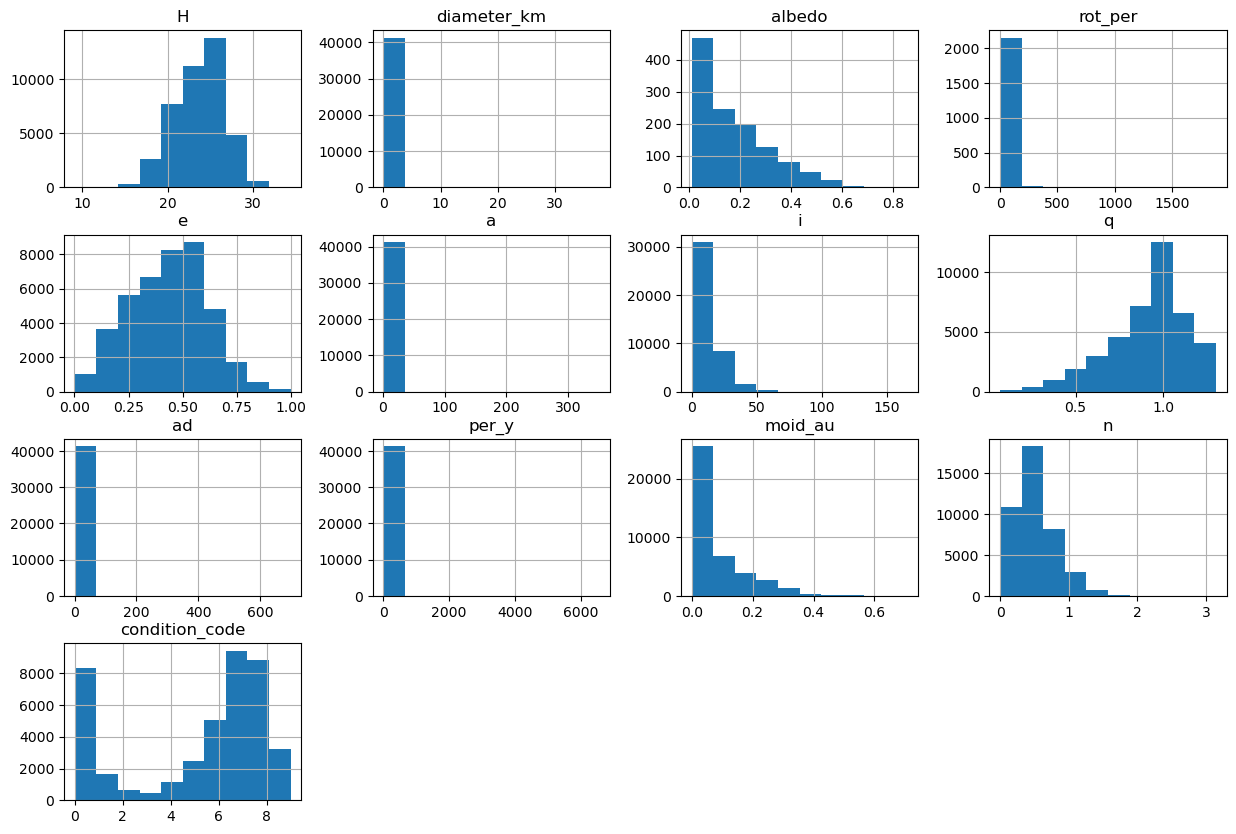

In [65]:
data_clean.hist(figsize=(15, 10))